# NLP Today Session 05: Creating Our Own Language Model

### Students:
- Zakaria SOUALAH MOHAMMED (zakaria.soualah-mohammed@universite-paris-saclay.fr)
- Wissam AMAR (wissam.amar@universite-paris-saclay.fr)

# Implementation of a transformer model
In this exercise we will implement the transformer model (an architecture based on LLama2). The squeleton of the code is provided and you should complete it (mostly self attention mechanism).

In [1]:
import time 
from time import gmtime, strftime
import math
import shutil
import os
import csv
import json
import sys
import hashlib
from pathlib import Path



# neural network utilities
import torch
from torch import nn
from torch import optim
from torch.nn import functional as F
from torch.utils.data import DataLoader

# dataset an tokenization
from datasets import load_dataset
from transformers import AutoTokenizer

from rope_embedding import RoPE


C:\Users\zakar\OneDrive\Bureau\M2 AI\NLP Today\NLP_labs_Saclay\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Self Attention with no mask

Let consider $Q, K, V \in R^{B\times H \times L \times N}$ for each batch element (B) for each heads (H) we want to compute $$A = \frac{Q_{bh}.K_{bh}^{t}}{\sqrt{N}}$$

Attention weights are defined by $$ 
softmax(A_i) = \begin{pmatrix}
\frac{e^{A_{i1}}}{\sum\limits_{j=1}^L  e^{A_{ij}}} & 
\frac{e^{A_{i2}}}{\sum\limits_{j=1}^L  e^{A_{ij}}} & 
\dots &
\frac{e^{A_{iL}}}{\sum\limits_{j=1}^L  e^{A_{ij}}}
\end{pmatrix}$$ 
And $$ 
Softmax(A) = \begin{pmatrix}
\frac{e^{A_{11}}}{\sum\limits_{j=1}^L  e^{A_{1j}}} & 
\frac{e^{A_{12}}}{\sum\limits_{j=1}^L  e^{A_{1j}}} & 
\dots &
\frac{e^{A_{1L}}}{\sum\limits_{j=1}^L  e^{A_{1j}}} \\
\frac{e^{A_{21}}}{\sum\limits_{j=1}^L  e^{A_{2j}}} & 
\frac{e^{A_{22}}}{\sum\limits_{j=1}^L  e^{A_{2j}}} & 
\dots &
\frac{e^{A_{2l}}}{\sum\limits_{j=1}^L  e^{A_{2j}}} \\
\vdots & \vdots & \ddots & \vdots \\
\frac{e^{A_{L1}}}{\sum\limits_{j=1}^L  e^{A_{Lj}}} & 
\frac{e^{A_{L2}}}{\sum\limits_{j=1}^L  e^{A_{Lj}}} & 
\dots &
\frac{e^{A_{LL}}}{\sum\limits_{j=1}^L  e^{A_{Lj}}}
\end{pmatrix}$$ 


Notice that the function softmax can be used to compute this matrix [`torch.softmax`](https://docs.pytorch.org/docs/stable/generated/torch.softmax.html#torch.softmax).


## Masked Attention
In many cases, certains tokens will not compute attention with later tokens (padding or decoding approaches). Typically in decoder only architectures we would have the attention weights matrix only considering lower diagonal values :

$$ 
Softmax(A) = \begin{pmatrix}
\frac{e^{A_{11}}}{\sum\limits_{j=1}^1  e^{A_{1j}}} & 
0 & 
\dots & 0 &
0 \\
\frac{e^{A_{21}}}{\sum\limits_{j=1}^2  e^{A_{2j}}} & 
\frac{e^{A_{22}}}{\sum\limits_{j=1}^2  e^{A_{2j}}} & 
\dots & 0 &
0 \\
\vdots & \vdots & \ddots & \vdots \\
\frac{e^{A_{{L-1}1}}}{\sum\limits_{j=1}^{L-1}  e^{A_{L-1j}}} & 
\frac{e^{A_{{L-1}2}}}{\sum\limits_{j=1}^{L-1}  e^{A_{L-1j}}} & 
\dots &
\frac{e^{A_{L-1L-1}}}{\sum\limits_{j=1}^{L-1}  e^{A_{L-1j}}}& 0 \\
\frac{e^{A_{L1}}}{\sum\limits_{j=1}^L  e^{A_{Lj}}} & 
\frac{e^{A_{L2}}}{\sum\limits_{j=1}^L  e^{A_{Lj}}} & 
\dots &
\frac{e^{A_{LL-1}}}{\sum\limits_{j=1}^L  e^{A_{Lj}}} & 
\frac{e^{A_{LL}}}{\sum\limits_{j=1}^L  e^{A_{Lj}}} \\
\end{pmatrix}$$ 

A simple implementation would consist in setting the upper diagonal of A to $-\infty$ and apply the softmax. We will thus consider a matrix name $M$ (or `mask` in the code) having upper diagonal element to $-\infty$ : 
$$ M = 
\begin{pmatrix}
0& 
-\infty & 
\dots & -\infty&
-\infty \\
0 & 
0 & 
\dots & -\infty &
-\infty \\
\vdots & \vdots & \ddots & \vdots \\
0 & 
0 & 
\dots &
0& -\infty \\
0 & 
0 & 
\dots &
0 & 
0\\
\end{pmatrix}
$$

And apply softmax on $A + M$

In [2]:
def multi_head_attention(
    q : torch.FloatTensor,
    k : torch.FloatTensor,
    v : torch.FloatTensor,
    mask : torch.FloatTensor
):
    """
    Given Q,K,V and the attention mask compute cross attention

    The shape of the matrix are the following:
    B: The batch size (number of examples)
    Q: The size of the decoder sequence
    K: The size of the encoder sequence
    H: Then number of attention heads
    N: The embedding size 
    
    Parameters:
        q : torch.FloatTensor
            The query matrix of shape BxHxQxN
        k : torch.FloatTensor
            The key matrix of shape BxHxKxN
        v : torch.FloatTensor
            The value matrix of shape BxHxKxN
        mask : torch.FloatTensor
            The attention mask of shape BxQxK,
            the masked elements are set to -inf 
            else elements are set to 0
    Return : (torch.Tensor, torch.Tensor)
        return two tensor the first containing 
        the attention weights (QK^t) and the second 
        the result of the attention
    """
    scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(q.size(-1))
    if mask is not None:
        if mask.ndim == 3:
            mask = mask.unsqueeze(1)
        scores = scores + mask.to(device=scores.device, dtype=scores.dtype)
    attention_weights = torch.softmax(scores.float(), dim=-1).to(v.dtype)
    attention_output = torch.matmul(attention_weights, v)
    return attention_weights, attention_output


In [3]:
q, k, v = (torch.ones(1, 1, 3, 4), torch.ones(1, 1, 3, 4), torch.ones(1, 1, 3, 4))
mask = torch.triu(-q.new_ones(1, 3, 3) *  torch.inf, diagonal =  1)
attention_weigths, attention_output = multi_head_attention(q, k, v, mask)

assert(torch.all(attention_weigths == torch.Tensor([
          [[[1., 0., 0.],
            [1/2, 1/2, 0.],
            [1/3, 1/3, 1/3]]]])))

##  Create the attention module

In pytorch module are block of neural networks that inherit from the class `nn.Module`.  In the following you willbe asked to complete the attention code. The attention module compute the Query $Q$, the Keys $K$ and Values $V$ for each heads and compute attention. The forward methods is the method implementing these operations. In this lab we use a mult-head attention, meaning that we compute attention for each heads, that can be done with a for loop or using batched operation (it is up to you). Also as we follow the Llama 2 architecture, we use for positional embeding the RoPe positonal encoding that is applied on the two matrix $Q$ and $K$. The forward function should compute for an input $X \in \mathbb{R}^{L \times N}$ (in the decoder only case) the following:

1. $Q_h = RoPE(W^q_{h}X^{\intercal})$ (for all heads h) with $W^q_h \in \mathbb{R}^{N \times N}$
2. $K_h = RoPE(W^k_{h}X^{\intercal})$ (for all heads h)
3. $V_h = W^v_{h}X^{\intercal}$ (for all heads h)
4. $A_h =  Attention(Q_h, K_h, V_h)$ (for all heads h)
5. $A$ = [A_1, A_2, \dots A_H] (the concatenation along the last dimension)
6. $O = W^oA^{\intercal}$ with $w^{o} \in \mathbb{R}^{N \times NH}$ (NH being the scalar multplication of N and H)

Notice that Q, K and V can be computed without a loop using $W_{q}$ (respectively for $W_k$ and $W_v$) .


In [4]:

class RoPEAttentionModule(nn.Module):
    """ A cross/self attention pytorch module.
    
    """
    def __init__(self, input_dim, output_dim, num_heads=1):
        super().__init__()
        
        self.Wq, self.Wk, self.Wv  =\
            (nn.Linear(input_dim, output_dim * num_heads) for _ in range(3))

        self.output_dim = output_dim
        self.num_heads = num_heads
        self.Wo = nn.Linear(output_dim * num_heads, input_dim)
        self.rope_func = RoPE(output_dim)
    
    def forward(
            self,
            x : torch.Tensor,
            attention_mask : torch.BoolTensor = None, 
            y : torch.Tensor = None,
            decoder_mask = True,
            k_cache = None,
            v_cache = None,
            start_cache = 0
        ):
        ''' 
            Parameters:
                x : torch.Tensor
                    The input of the Attention module
                    used at least for K, V computation
                    (for Q if decoder only)
                attention_mask : torch.BoolTensor
                    The mask for attention
                y : torch.Tensor or None
                    The query input in the case of
                    cross-attention
        '''
        batch_size, key_length, _ = x.shape
        query_input = x if y is None else y
        query_length = query_input.size(1)
        q = self.Wq(query_input).view(batch_size, query_length, self.num_heads, self.output_dim).transpose(1, 2)
        k = self.Wk(x).view(batch_size, key_length, self.num_heads, self.output_dim).transpose(1, 2)
        v = self.Wv(x).view(batch_size, key_length, self.num_heads, self.output_dim).transpose(1, 2)
        q = self.rope_func(q, start_pos_id=start_cache)
        k = self.rope_func(k, start_pos_id=start_cache if y is None else 0)

        if (k_cache is None) != (v_cache is None):
            raise ValueError("Provide both key and value caches.")
        if k_cache is not None:
            if y is not None:
                raise ValueError("KV caching is supported for self-attention only.")
            end_cache = start_cache + key_length
            if start_cache < 0 or end_cache > k_cache.size(2):
                raise ValueError("The sequence exceeds the KV cache capacity.")
            k_cache[:, :, start_cache:end_cache].copy_(k)
            v_cache[:, :, start_cache:end_cache].copy_(v)
            k = k_cache[:, :, :end_cache]
            v = v_cache[:, :, :end_cache]
        elif start_cache:
            raise ValueError("A nonzero cache position requires KV caches.")

        mask = q.new_zeros(batch_size, query_length, k.size(2))
        if decoder_mask:
            query_positions = torch.arange(query_length, device=x.device) + start_cache
            key_positions = torch.arange(k.size(2), device=x.device)
            mask.masked_fill_(key_positions[None, :] > query_positions[:, None], -torch.inf)
        if attention_mask is not None:
            # True marks padding, as in the mask suggested in the training cell.
            padding_mask = attention_mask.to(device=x.device)
            if padding_mask.dtype == torch.bool:
                if padding_mask.ndim == 2:
                    padding_mask = padding_mask.unsqueeze(1)
                mask = mask.masked_fill(padding_mask, -torch.inf)
            else:
                if padding_mask.ndim == 2:
                    padding_mask = padding_mask.unsqueeze(1)
                mask = mask + padding_mask
        attention_weigths, attended = multi_head_attention(q, k, v, mask)
        output = self.Wo(attended.transpose(1, 2).contiguous().view(batch_size, query_length, -1))

        return attention_weigths, output

    


    



## Trasnsformer FeedForward

The FeedForward Network is defined using Llama 2 architecture as following for $X \in \mathbb{R^{L\times N}}$ :


1. $G = SiLU(W^gX^\intercal)$ with $W^g \in \mathbb{R}^{M \times N}$ (see SiLU in pytorch [documentation](https://docs.pytorch.org/docs/stable/generated/torch.nn.SiLU.html))
2. $U = W^u X^\intercal$ with $W^u  \in \mathbb{R}^{M \times N}$
3. $I = G \odot I$ (Hadamard multiplication)
4. $O = W^{o} I^{\intercal}$ with $W_{o} \in \mathbb{R}^{N \times M}$






In [5]:
class TransformerFeedForward(nn.Module):
    def __init__(self, embed_size, intermediate_size):
        super().__init__()
        self.gate_proj = nn.Linear(embed_size, intermediate_size)
        self.up_proj = nn.Linear(embed_size, intermediate_size)
        self.down_proj = nn.Linear(intermediate_size, embed_size)
        self.gate_func = nn.SiLU()
        
    def forward(self, x):
        return self.down_proj(self.gate_func(self.gate_proj(x)) * self.up_proj(x))

## Transformer block
We can now create the block of the 

Let consider $x_0 \in \mathbb{R}^{B \times L \times N}$, the decoder block is given by : 

* $x_1 = LN_1(x_0)$ (apply layer norm)
* $x_2 = Attention(x_1)$ (apply attention)
* $x_3 = x_0 + x_2$ (adding residual)
* $x_4 = LN_2(x_3)$
* $y = FF(x_4) + x_4$


In [6]:
class TransformerDecoderBlock(nn.Module):
    def __init__(self, embed_size, intermediate_size, num_heads):
        super().__init__()
        self.attention_module =\
            RoPEAttentionModule(embed_size, embed_size, num_heads=num_heads)
        self.feed_forward = TransformerFeedForward(embed_size, intermediate_size)
        
        self.attention_layer_norm = nn.RMSNorm(embed_size)
        self.feed_forward_layer_norm = nn.RMSNorm(embed_size)
        
    def forward(
        self,
        x,
        attention_mask = None,
        k_cache=None,
        v_cache=None,
        start_cache=0,
        layer=0,
    ):
        
        normalized = self.attention_layer_norm(x)
        _, attended = self.attention_module(
            normalized, attention_mask=attention_mask,
            k_cache=None if k_cache is None else k_cache[layer],
            v_cache=None if v_cache is None else v_cache[layer],
            start_cache=start_cache,
        )
        residual = x + attended
        output = residual + self.feed_forward(self.feed_forward_layer_norm(residual))
        
        return output

## The Model

The model contain a stack of block on input embedding, it applies the different transformation and should return both the output embeddings and the logits (size of the vocabulary).

It should return $o_{e} \mathbb{R}^{B\times L \times N}$ and $\hat{y}\in \mathbb{R}^{B\times L \times V}$ with : 

* $o_e = RMSNORM \left( b_h\circ \dots   \circ \circ b_2 \circ b_1 (w_{word\_embedding}x^\intercal) \right)$ with $b_i$ the $i^{th}$ block
* $\hat{y} = W_{lm\_head} o_e^{T}$



In [7]:
class TransformerDecoder(nn.Module):
    def __init__(self, vocabulary_size, embed_size, intermediate_size, num_heads, hidden_layers=5, **kwargs):
        super().__init__(**kwargs)
        self.nh = num_heads
        self.nhl = hidden_layers
        self.es = embed_size 

        self.wte = nn.Embedding(vocabulary_size, embed_size)

        self.blocks = nn.ModuleList([TransformerDecoderBlock(embed_size, intermediate_size, num_heads) for _ in range(hidden_layers)])
        self.ln_f = nn.RMSNorm(embed_size, eps=1e-3)
        self.lm_head = nn.Linear(embed_size, vocabulary_size)


    def forward(
            self,
            input_ids,
            attention_mask = None,
            k_cache = None,
            v_cache = None,
            start_cache = 0
        ):
        

        input_embed = self.wte(input_ids) 
        intermediate = input_embed 

        for i, block in enumerate(self.blocks):
            intermediate = block(
                intermediate, attention_mask=attention_mask,
                k_cache=k_cache, v_cache=v_cache,
                start_cache=start_cache, layer=i,
            )

        
        output_embed = self.ln_f(intermediate)
        output_lm = self.lm_head(output_embed)  

        return output_embed, output_lm

##  Training the transformer

### I.Dataset 
For simplicity we will use a small dataset name TinyStories, we can load it using the huggingface Datasets library as following

In [8]:
# Short training run; choose these values before running the notebook.
batch_size = 16
max_steps = 5000
microbatch_token_budget = 4096
microbatch_attention_budget = 4 * 1024**2
learning_rate = 6e-4
use_amp = True
seed = 42
validation_batches = 4
validation_every = 250
checkpoint_every = 1000
run_dir = Path('runs') / time.strftime('lm5000_%Y%m%d_%H%M%S', gmtime())
run_dir.mkdir(parents=True, exist_ok=False)
print(f"Run artifacts: {run_dir.resolve()}", flush=True)

torch.manual_seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

# Only fetch the examples needed for this run.
tinystories_dataset = load_dataset("roneneldan/TinyStories", streaming=True)
training_set = list(tinystories_dataset['train'].shuffle(seed=seed, buffer_size=1000).take(max_steps * batch_size))
validation_set = list(tinystories_dataset['validation'].take(validation_batches * batch_size))
print(training_set[0])


Run artifacts: C:\Users\zakar\OneDrive\Bureau\M2 AI\NLP Today\NLP_labs_Saclay\Lab5_LM_Transformers\New_Part1\runs\lm5000_20261024_170439


{'text': 'Once upon a time, there was a nation of people. They lived together, but they sometimes quarreled with each other. One day a little girl named Alice noticed that the nation was not happy. She wanted them to get along, so she decided to share her special gifts with everyone. \n\nAlice had a wagon full of toys and snacks. She gave away her favorite things to all of her friends and family. She also spoiled her own little pet puppy with treats. \n\nThe nation of people saw how Alice was spreading joy and smiles, and they realized that they could do the same. Instead of quarreling, they started doing nice things for each other. Soon, the nation was a much better place. \n\nAlice was happy to see that her simple act of kindness had made a big difference. She was glad that all the people in the nation were now happy and getting along with each other.'}


### The Dataloader

We can define the batch_size default we will use, using the DataLoader object. Here we consider that the training machine will have enough RAM for a batch of 16 samples.

In [9]:
training_dl = DataLoader(training_set, batch_size=batch_size, shuffle=True,
                         generator=torch.Generator().manual_seed(seed))
validation_dl = DataLoader(validation_set, batch_size=batch_size, shuffle=False) 

### III. Tokenizer

In this exercice we will consider the LLama Tokenizer, however, you can train your own tokenizer if you prefer (see lab 2)

In [10]:


os.environ["TOKENIZERS_PARALLELISM"] = "false"

model_hg_id = "mistralai/Mistral-7B-v0.3"

tokenizer = AutoTokenizer.from_pretrained(model_hg_id)
tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = 'right' 
vocabulary_size = 32768
assert tokenizer.vocab_size == vocabulary_size and len(tokenizer) == vocabulary_size

### IV. Create the model and the optimizer

In [11]:
if not torch.cuda.is_available():
    raise RuntimeError("Select a Python kernel with CUDA-enabled PyTorch to use the GPU.")
device = 'cuda'
torch.set_float32_matmul_precision('high')
model_config = dict(vocabulary_size=32768, embed_size=256, intermediate_size=512,
                    num_heads=4, hidden_layers=8)
model = TransformerDecoder(**model_config)
model = model.train()
model = model.to(device)
loss_function = nn.CrossEntropyLoss(ignore_index=-100)
optimizer = optim.AdamW(model.parameters(), lr=learning_rate)
use_amp = use_amp and torch.cuda.is_bf16_supported()
print(f"GPU: {torch.cuda.get_device_name(0)}; parameters: {sum(p.numel() for p in model.parameters()):,}; BF16: {use_amp}")

import datasets
import transformers

run_config = {
    'initialization': 'from_scratch',
    'model': model_config,
    'parameter_count': sum(parameter.numel() for parameter in model.parameters()),
    'max_steps': max_steps,
    'batch_size': batch_size,
    'learning_rate': learning_rate,
    'optimizer': 'AdamW',
    'betas': list(optimizer.param_groups[0]['betas']),
    'weight_decay': optimizer.param_groups[0]['weight_decay'],
    'gradient_clip_norm': 1.0,
    'seed': seed,
    'precision': 'BF16 autocast with FP32 parameters' if use_amp else 'FP32',
    'matmul_precision': torch.get_float32_matmul_precision(),
    'truncation': False,
    'microbatch_token_budget': microbatch_token_budget,
    'microbatch_attention_budget': microbatch_attention_budget,
    'dataset': 'roneneldan/TinyStories',
    'training_split': 'train',
    'selected_training_stories': len(training_set),
    'stream_shuffle_buffer': 1000,
    'validation_split': 'validation',
    'validation_stories': len(validation_set),
    'validation_every_steps': validation_every,
    'checkpoint_every_steps': checkpoint_every,
    'tokenizer': model_hg_id,
    'padding_side': tokenizer.padding_side,
    'padding_token_id': tokenizer.pad_token_id,
    'gpu': torch.cuda.get_device_name(0),
    'gpu_total_memory_gib': torch.cuda.get_device_properties(0).total_memory / 1024**3,
    'python': sys.version,
    'python_executable': sys.executable,
    'torch': str(torch.__version__),
    'cuda': torch.version.cuda,
    'transformers': transformers.__version__,
    'datasets': datasets.__version__,
    'started_at_utc': strftime('%Y-%m-%dT%H:%M:%SZ', gmtime()),
    'rope_source_sha256': hashlib.sha256(Path('rope_embedding.py').read_bytes()).hexdigest(),
}
notebook_source = json.loads(Path('implement_transformer.ipynb').read_text(encoding='utf-8'))
code_source = '\n'.join(''.join(cell['source']) for cell in notebook_source['cells'] if cell['cell_type'] == 'code')
run_config['notebook_code_sha256'] = hashlib.sha256(code_source.encode('utf-8')).hexdigest()
(run_dir / 'run_config.json').write_text(json.dumps(run_config, indent=2), encoding='utf-8')
print('Fresh random initialization; training metrics will be saved after every optimizer update.')


GPU: NVIDIA GeForce RTX 3060 Laptop GPU; parameters: 28,385,536; BF16: True
Fresh random initialization; training metrics will be saved after every optimizer update.


In [12]:
model

TransformerDecoder(
  (wte): Embedding(32768, 256)
  (blocks): ModuleList(
    (0-7): 8 x TransformerDecoderBlock(
      (attention_module): RoPEAttentionModule(
        (Wq): Linear(in_features=256, out_features=1024, bias=True)
        (Wk): Linear(in_features=256, out_features=1024, bias=True)
        (Wv): Linear(in_features=256, out_features=1024, bias=True)
        (Wo): Linear(in_features=1024, out_features=256, bias=True)
      )
      (feed_forward): TransformerFeedForward(
        (gate_proj): Linear(in_features=256, out_features=512, bias=True)
        (up_proj): Linear(in_features=256, out_features=512, bias=True)
        (down_proj): Linear(in_features=512, out_features=256, bias=True)
        (gate_func): SiLU()
      )
      (attention_layer_norm): RMSNorm((256,), eps=None, elementwise_affine=True)
      (feed_forward_layer_norm): RMSNorm((256,), eps=None, elementwise_affine=True)
    )
  )
  (ln_f): RMSNorm((256,), eps=0.001, elementwise_affine=True)
  (lm_head): Linear

### VI. Training the model

In [13]:
def encode_stories(data):
    # Keep every token; padding is added only within each GPU microbatch.
    encoded = tokenizer(data['text'], padding=False, truncation=False)
    return [dict(input_ids=ids, attention_mask=mask)
            for ids, mask in zip(encoded.input_ids, encoded.attention_mask)]


def split_microbatches(examples, token_budget=microbatch_token_budget,
                       attention_budget=microbatch_attention_budget):
    groups, current = [], []
    longest = 0
    for example in sorted(examples, key=lambda item: len(item['input_ids'])):
        candidate_length = max(longest, len(example['input_ids']))
        candidate_size = len(current) + 1
        if current and (candidate_size * candidate_length > token_budget or
                        candidate_size * candidate_length**2 > attention_budget):
            groups.append(current)
            current, longest = [], 0
        current.append(example)
        longest = max(longest, len(example['input_ids']))
    if current:
        groups.append(current)
    return groups


def prepare_batch(examples):
    res = tokenizer.pad(examples, padding=True, return_tensors="pt")
    x = res.input_ids[:, :-1].to(device)
    y = res.input_ids[:, 1:].clone().to(device)
    y.masked_fill_(res.attention_mask[:, 1:].to(device) == 0, -100)
    expected_tokens = sum(len(example['input_ids']) - 1 for example in examples)
    assert (y != -100).sum().item() == expected_tokens, "Some story tokens were lost."
    return x, y, res.attention_mask[:, :-1].to(device) == 0


@torch.no_grad()
def evaluate_loss(model, dataloader):
    was_training = model.training
    model.eval()
    total_loss, total_tokens, total_stories = 0.0, 0, 0
    longest_story = 0
    for data in dataloader:
        examples = encode_stories(data)
        total_stories += len(examples)
        longest_story = max(longest_story, max(len(example['input_ids']) for example in examples))
        for microbatch in split_microbatches(examples):
            x, y, padding_mask = prepare_batch(microbatch)
            with torch.autocast(device_type='cuda', dtype=torch.bfloat16, enabled=use_amp):
                _, logits = model(x, attention_mask=padding_mask)
                loss_sum = F.cross_entropy(logits.reshape(-1, vocabulary_size),
                                           y.reshape(-1), ignore_index=-100, reduction='sum')
            total_loss += loss_sum.item()
            total_tokens += (y != -100).sum().item()
    model.train(was_training)
    print(f"Evaluated {total_stories} complete stories, {total_tokens:,} target tokens; longest story: {longest_story} tokens")
    evaluate_loss.last_statistics = {
        'stories': total_stories, 'target_tokens': total_tokens,
        'max_story_tokens': longest_story,
    }
    return total_loss / total_tokens


training_history = []
validation_history = []
training_losses = []
avg_loss = []
training_stories_seen = 0
training_tokens_seen = 0
longest_training_story = 0
cumulative_training_seconds = 0.0
training_text_hasher = hashlib.sha256()
train_fields = [
    'step', 'train_loss', 'train_loss_token_weighted_mean_100', 'learning_rate',
    'grad_norm_before_clipping', 'step_seconds', 'cumulative_training_seconds',
    'wall_seconds', 'batch_stories', 'batch_target_tokens', 'max_story_tokens',
    'microbatches', 'stories_seen', 'target_tokens_seen', 'target_tokens_per_second',
    'gpu_peak_allocated_gib', 'gpu_peak_reserved_gib',
]
validation_fields = [
    'step', 'validation_loss', 'validation_perplexity', 'stories', 'target_tokens',
    'max_story_tokens', 'evaluation_seconds', 'cumulative_training_seconds', 'wall_seconds',
]
train_log = (run_dir / 'training_metrics.csv').open('w', newline='', encoding='utf-8')
validation_log = (run_dir / 'validation_metrics.csv').open('w', newline='', encoding='utf-8')
train_writer = csv.DictWriter(train_log, fieldnames=train_fields)
validation_writer = csv.DictWriter(validation_log, fieldnames=validation_fields)
train_writer.writeheader()
validation_writer.writeheader()
train_log.flush()
validation_log.flush()
run_started = time.perf_counter()


def record_validation(step):
    evaluation_started = time.perf_counter()
    value = evaluate_loss(model, validation_dl)
    torch.cuda.synchronize()
    record = dict(
        step=step, validation_loss=value, validation_perplexity=math.exp(value),
        **evaluate_loss.last_statistics,
        evaluation_seconds=time.perf_counter() - evaluation_started,
        cumulative_training_seconds=cumulative_training_seconds,
        wall_seconds=time.perf_counter() - run_started,
    )
    validation_history.append(record)
    validation_writer.writerow(record)
    validation_log.flush()
    print(f"Validation at step {step}: loss {value:.4f}; perplexity {math.exp(value):.2f}", flush=True)
    return value


def save_training_checkpoint(step):
    # Save optimizer moments and RNG state as well as weights for a future continuation.
    checkpoint = {
        'completed_steps': step,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'model_config': model_config,
        'run_config': run_config,
        'training_history': training_history,
        'validation_history': validation_history,
        'stories_seen': training_stories_seen,
        'target_tokens_seen': training_tokens_seen,
        'training_text_order_sha256': training_text_hasher.hexdigest(),
        'torch_rng_state': torch.get_rng_state(),
        'cuda_rng_states': torch.cuda.get_rng_state_all(),
        'dataloader_generator_state': training_dl.generator.get_state(),
    }
    temporary_path = run_dir / 'training_checkpoint.pth.temp'
    torch.save(checkpoint, temporary_path)
    os.replace(temporary_path, run_dir / 'training_checkpoint.pth')
    print(f"Saved recovery checkpoint at step {step}.", flush=True)


initial_validation_loss = record_validation(0)
print(f"Initial validation loss: {initial_validation_loss:.4f}; perplexity: {math.exp(initial_validation_loss):.2f}")
model = model.train()
start_time = time.perf_counter()

for i, data in enumerate(training_dl):
    if i >= max_steps:
        break
    step_started = time.perf_counter()
    torch.cuda.reset_peak_memory_stats()
    examples = encode_stories(data)
    total_tokens = sum(len(example['input_ids']) - 1 for example in examples)
    microbatches = split_microbatches(examples)
    # attention_mask = (res.attention_mask == 0)
    optimizer.zero_grad(set_to_none=True)
    loss_value = 0.0
    for microbatch in microbatches:
        x, y, padding_mask = prepare_batch(microbatch)
        with torch.autocast(device_type='cuda', dtype=torch.bfloat16, enabled=use_amp):
            oe, oy = model(x, attention_mask=padding_mask)
            # Weight by real token count so accumulation matches a full batch of 16 stories.
            loss = F.cross_entropy(oy.reshape(-1, vocabulary_size), y.reshape(-1),
                                   ignore_index=-100, reduction='sum') / total_tokens
        if not torch.isfinite(loss):
            raise RuntimeError(f"Non-finite loss at step {i + 1}.")
        loss.backward()
        loss_value += loss.item()
        del oe, oy, loss
    grad_norm = nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0, error_if_nonfinite=True)
    optimizer.step()
    torch.cuda.synchronize()
    step_seconds = time.perf_counter() - step_started
    cumulative_training_seconds += step_seconds
    training_stories_seen += len(examples)
    training_tokens_seen += total_tokens
    batch_max_length = max(len(example['input_ids']) for example in examples)
    longest_training_story = max(longest_training_story, batch_max_length)
    for text in data['text']:
        raw_text = text.encode('utf-8')
        training_text_hasher.update(len(raw_text).to_bytes(8, 'little'))
        training_text_hasher.update(raw_text)
    record = dict(
        step=i+1, train_loss=loss_value, learning_rate=optimizer.param_groups[0]['lr'],
        grad_norm_before_clipping=grad_norm.item(), step_seconds=step_seconds,
        cumulative_training_seconds=cumulative_training_seconds,
        wall_seconds=time.perf_counter() - run_started,
        batch_stories=len(examples), batch_target_tokens=total_tokens,
        max_story_tokens=batch_max_length, microbatches=len(microbatches),
        stories_seen=training_stories_seen, target_tokens_seen=training_tokens_seen,
        target_tokens_per_second=total_tokens / step_seconds,
        gpu_peak_allocated_gib=torch.cuda.max_memory_allocated() / 1024**3,
        gpu_peak_reserved_gib=torch.cuda.max_memory_reserved() / 1024**3,
    )
    window = training_history[-99:] + [record]
    record['train_loss_token_weighted_mean_100'] = (
        sum(row['train_loss'] * row['batch_target_tokens'] for row in window)
        / sum(row['batch_target_tokens'] for row in window)
    )
    training_history.append(record)
    train_writer.writerow(record)
    train_log.flush()
    training_losses.append(loss_value)
    avg_loss.append(loss_value)
    if (i + 1) % 10 == 0 or i == 0 or i + 1 == max_steps:
        elapsed_time = time.perf_counter() - start_time
        remaining_time = int((elapsed_time/(i+1)) * (min(max_steps, len(training_dl)) - i - 1))
        loop_sec = ((i+1)/elapsed_time)
        print(f"The loss at iteration {i+1} is {sum(avg_loss)/len(avg_loss):3.4f} remaining_time is {strftime('%H:%M:%S', gmtime(remaining_time))}s ({loop_sec:4.1f} it/s)", flush=True)
        avg_loss = []
    if (i + 1) % validation_every == 0 and i + 1 < max_steps:
        record_validation(i + 1)
    if (i + 1) % checkpoint_every == 0:
        save_training_checkpoint(i + 1)

train_log.close()
training_seconds = cumulative_training_seconds
peak_memory_gb = max(row['gpu_peak_allocated_gib'] for row in training_history)
# Keep the downloaded optimizer file intact; its shapes belong to a smaller model.
torch.save(model.state_dict(), run_dir / 'model_state_dict.pth.temp')
os.replace(run_dir / 'model_state_dict.pth.temp', run_dir / 'model_state_dict.pth')
assert training_stories_seen == max_steps * batch_size
assert {int(state['step'].item()) for state in optimizer.state.values()} == {max_steps}
print(f"Finished {len(training_losses)} steps in {training_seconds:.1f}s of updates; peak GPU memory: {peak_memory_gb:.2f} GiB")
print(f"Trained on {training_stories_seen:,} complete stories, {training_tokens_seen:,} target tokens; longest story: {longest_training_story} tokens")


You're using a LlamaTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.


Evaluated 64 complete stories, 11,371 target tokens; longest story: 317 tokens
Validation at step 0: loss 10.5522; perplexity 38263.19


Initial validation loss: 10.5522; perplexity: 38263.19


The loss at iteration 1 is 10.5559 remaining_time is 00:48:18s ( 1.7 it/s)


The loss at iteration 10 is 8.8323 remaining_time is 00:27:17s ( 3.0 it/s)


...

The loss at iteration 4990 is 1.9582 remaining_time is 00:00:03s ( 3.2 it/s)


The loss at iteration 5000 is 1.9706 remaining_time is 00:00:00s ( 3.2 it/s)


Saved recovery checkpoint at step 5000.


Finished 5000 steps in 1553.4s of updates; peak GPU memory: 3.17 GiB


Trained on 80,000 complete stories, 18,499,354 target tokens; longest story: 1177 tokens


## Decoding time

There is different way to decode, the simplest one is the greedy decoding method, the principle is to loop with the new token produced each time (complete `nonefficient_greedy_decoding`) and choosing the token the most likely. We can also store Keys and Values as shown in course that in practice only accellerate the generation but not change it (complete `greedy_decoding`). And finally we can also sampling new tokens (complete `sampling_decoding` ).

In [14]:
@torch.no_grad()
def nonefficient_greedy_decoding(model, x, max_new_tokens=64):
    model.eval()
    previous_gen = x.to(next(model.parameters()).device)
    for _ in range(max_new_tokens):
        _, logits = model(previous_gen)
        next_token = logits[:, -1].argmax(dim=-1, keepdim=True)
        previous_gen = torch.cat((previous_gen, next_token), dim=1)
    
    return previous_gen


def _cached_decoding(model, x, max_new_tokens, max_cache_size, tokenizer, temperature=None):
    model.eval()
    device = next(model.parameters()).device
    previous_gen = x.to(device)
    if previous_gen.ndim != 2 or previous_gen.size(1) == 0:
        raise ValueError("Provide a nonempty batch of token sequences.")
    if max_new_tokens < 0:
        raise ValueError("max_new_tokens must be nonnegative.")
    required_size = previous_gen.size(1) + max_new_tokens
    if required_size > max_cache_size:
        raise ValueError("Increase max_cache_size to fit the prompt and generated tokens.")
    if max_new_tokens == 0:
        return previous_gen
    cache_shape = (model.nhl, previous_gen.size(0), model.nh, required_size, model.es)
    k_cache = torch.empty(cache_shape, device=device, dtype=next(model.parameters()).dtype)
    v_cache = torch.empty_like(k_cache)
    current_input = previous_gen
    start_cache = 0
    finished = torch.zeros(previous_gen.size(0), dtype=torch.bool, device=device)
    eos_token_id = None if tokenizer is None else tokenizer.eos_token_id

    for _ in range(max_new_tokens):
        _, logits = model(current_input, k_cache=k_cache, v_cache=v_cache, start_cache=start_cache)
        last_logits = logits[:, -1].float()
        if temperature is None:
            next_token = last_logits.argmax(dim=-1, keepdim=True)
        else:
            probabilities = torch.softmax(last_logits / temperature, dim=-1)
            next_token = torch.multinomial(probabilities, num_samples=1)
        if eos_token_id is not None:
            next_token = torch.where(finished[:, None], eos_token_id, next_token)
            finished |= next_token[:, 0] == eos_token_id
        previous_gen = torch.cat((previous_gen, next_token), dim=1)
        start_cache += current_input.size(1)
        current_input = next_token
        if eos_token_id is not None and finished.all():
            break
    return previous_gen


@torch.no_grad()
def greedy_decoding(model, x, max_new_tokens=64, max_cache_size=512, tokenizer=None):
    return _cached_decoding(model, x, max_new_tokens, max_cache_size, tokenizer)


@torch.no_grad()
def sampling_decoding(model, x, max_new_tokens=64, max_cache_size=512, tokenizer=None, temperature=.7):
    if temperature <= 0:
        raise ValueError("temperature must be positive.")
    return _cached_decoding(model, x, max_new_tokens, max_cache_size, tokenizer, temperature)


In [15]:
model = TransformerDecoder(**model_config)
model.load_state_dict(torch.load(run_dir / 'model_state_dict.pth', map_location="cpu", weights_only=True))
model = model.eval()

decoding_method = greedy_decoding

text = "Alice"
model.to(device)

tokenized_text = tokenizer(text, return_tensors='pt')

output_ids = decoding_method(model, tokenized_text.input_ids.to(device), max_new_tokens=64, tokenizer=tokenizer)
print(tokenizer.batch_decode(output_ids, skip_special_tokens=True)[0])


Alice was a very happy three year old. She loved to explore and learn new things. One day, she decided to go to the park. As she was walking, she saw a big, scary dog. She was scared and ran away.

Alice wanted to get closer, so she reached out her hand and


## Evaluation ?

It remains difficult to evaluate the model. You can here propose an evalaution based on perplexity using an other model, or comparing results to ground truth using the test (here only validation) set, but it will not be totally informative !!!

In [16]:
validation_dataset = tinystories_dataset['validation']
final_validation_loss = record_validation(max_steps)
final_perplexity = math.exp(final_validation_loss)
print(f"Final validation loss: {final_validation_loss:.4f}; perplexity: {final_perplexity:.2f}")
print(f"Validation loss change: {final_validation_loss - initial_validation_loss:+.4f}")
assert math.isfinite(final_validation_loss)
assert len(training_losses) == max_steps

# Cached decoding should reproduce the full-prefix decoder.
prompt = tokenized_text.input_ids.to(device)
uncached_ids = nonefficient_greedy_decoding(model, prompt, max_new_tokens=8)
cached_ids = greedy_decoding(model, prompt, max_new_tokens=8)
assert torch.equal(uncached_ids, cached_ids), "Cached and uncached greedy decoding disagree."
sampled_ids = sampling_decoding(model, prompt, max_new_tokens=16, tokenizer=tokenizer)
assert sampled_ids.size(1) <= prompt.size(1) + 16
assert ((sampled_ids >= 0) & (sampled_ids < vocabulary_size)).all()
print("Cached greedy decoding matches full-prefix decoding; sampling returns valid token IDs.")
print("Sample:", tokenizer.batch_decode(sampled_ids, skip_special_tokens=True)[0])

validation_log.close()
# Include the final validation record in the checkpoint used for later analysis.
save_training_checkpoint(max_steps)
run_summary = {
    'status': 'completed', 'initialization': 'from_scratch',
    'completed_steps': len(training_history),
    'training_stories': training_stories_seen,
    'training_target_tokens': training_tokens_seen,
    'longest_training_story_tokens': longest_training_story,
    'validation_stories': validation_history[-1]['stories'],
    'validation_target_tokens': validation_history[-1]['target_tokens'],
    'initial_validation_loss': initial_validation_loss,
    'final_validation_loss': final_validation_loss,
    'initial_validation_perplexity': math.exp(initial_validation_loss),
    'final_validation_perplexity': final_perplexity,
    'training_update_seconds': training_seconds,
    'total_validation_seconds': sum(row['evaluation_seconds'] for row in validation_history),
    'wall_seconds_from_initial_validation': time.perf_counter() - run_started,
    'peak_training_gpu_allocated_gib': peak_memory_gb,
    'validation_evaluations': len(validation_history),
    'training_text_order_sha256': training_text_hasher.hexdigest(),
    'finite_loss_and_gradient_checks': 'passed on every update',
    'cached_greedy_equivalence': 'passed',
    'sampling_token_range_check': 'passed',
    'validation_scope': '64 complete held-out stories; not the entire validation split',
    'finished_at_utc': strftime('%Y-%m-%dT%H:%M:%SZ', gmtime()),
}
(run_dir / 'run_summary.json').write_text(json.dumps(run_summary, indent=2), encoding='utf-8')
generation_samples = {
    'prompt': text,
    'greedy': tokenizer.batch_decode(output_ids, skip_special_tokens=True)[0],
    'sampling_temperature_0_7': tokenizer.batch_decode(sampled_ids, skip_special_tokens=True)[0],
}
(run_dir / 'generation_samples.json').write_text(json.dumps(generation_samples, indent=2), encoding='utf-8')
print(f"Saved {len(training_history)} training rows and {len(validation_history)} validation rows for the report.")


Evaluated 64 complete stories, 11,371 target tokens; longest story: 317 tokens
Validation at step 5000: loss 1.7100; perplexity 5.53


Final validation loss: 1.7100; perplexity: 5.53
Validation loss change: -8.8423


Cached greedy decoding matches full-prefix decoding; sampling returns valid token IDs.
Sample: Alicey was a very pretty girl. She was three years old and she loved playing


Saved recovery checkpoint at step 5000.


Saved 5000 training rows and 21 validation rows for the report.


## Training records for the report
The CSV files retain every update and periodic held-out evaluation. The plots use a token-weighted mean over 100 updates to show the training trend. Timing separates optimizer updates from validation, and memory reports allocated GPU memory.

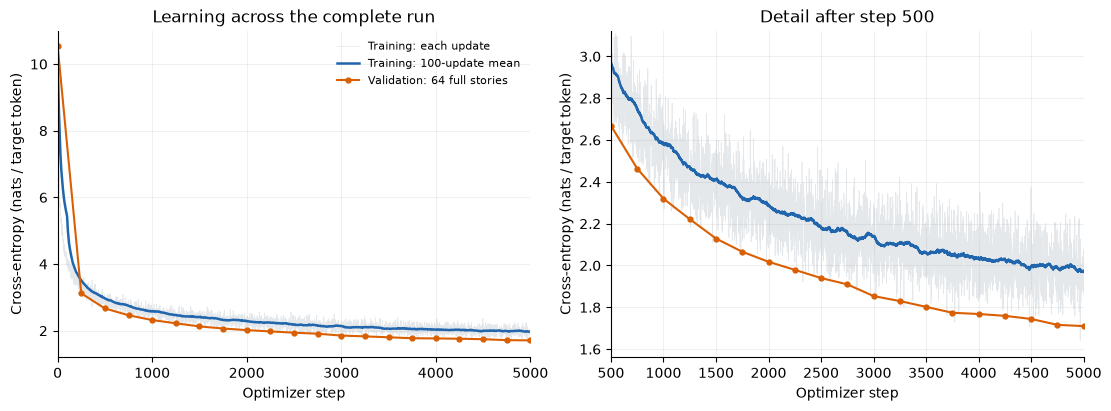

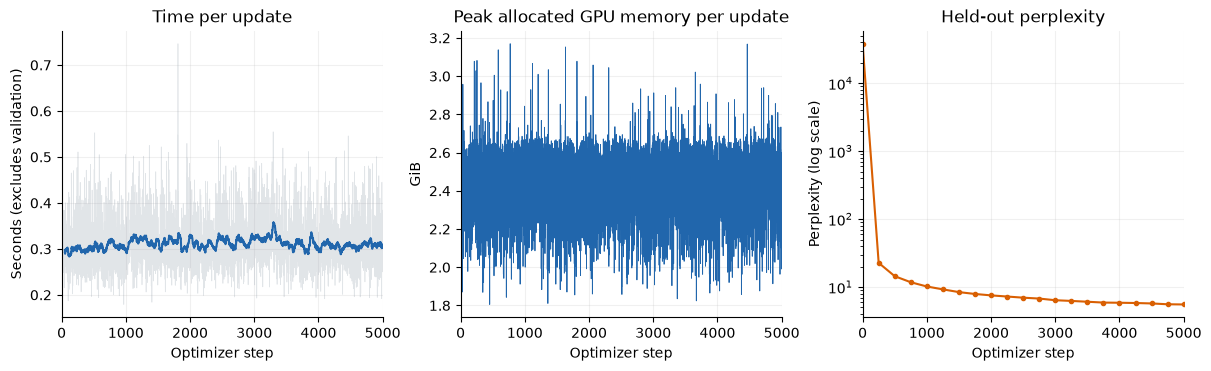

Report figures and raw metrics: C:\Users\zakar\OneDrive\Bureau\M2 AI\NLP Today\NLP_labs_Saclay\Lab5_LM_Transformers\New_Part1\runs\lm5000_20261024_170439


In [17]:
import matplotlib.pyplot as plt
import numpy as np

steps = np.array([row['step'] for row in training_history])
losses = np.array([row['train_loss'] for row in training_history])
smoothed_losses = np.array([row['train_loss_token_weighted_mean_100'] for row in training_history])
val_steps = np.array([row['step'] for row in validation_history])
val_losses = np.array([row['validation_loss'] for row in validation_history])
val_perplexities = np.array([row['validation_perplexity'] for row in validation_history])

plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
                     'savefig.dpi': 300, 'svg.fonttype': 'none'})
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for ax in axes:
    ax.plot(steps, losses, color='#8b98a5', alpha=0.22, linewidth=0.5, label='Training: each update')
    ax.plot(steps, smoothed_losses, color='#2166ac', linewidth=1.8, label='Training: 100-update mean')
    ax.plot(val_steps, val_losses, 'o-', color='#d95f02', markersize=3.5, linewidth=1.5, label='Validation: 64 full stories')
    ax.set_xlabel('Optimizer step')
    ax.set_ylabel('Cross-entropy (nats / target token)')
    ax.grid(alpha=0.18)
axes[0].set_title('Learning across the complete run')
axes[0].set_xlim(0, max_steps)
axes[0].legend(fontsize=8, frameon=False)
axes[1].set_title('Detail after step 500')
axes[1].set_xlim(500, max_steps)
late_values = np.r_[smoothed_losses[steps >= 500], val_losses[val_steps >= 500]]
axes[1].set_ylim(max(0, late_values.min() - 0.15), late_values.max() + 0.15)
fig.savefig(run_dir / 'learning_curves.png', bbox_inches='tight')
fig.savefig(run_dir / 'learning_curves.svg', bbox_inches='tight')
plt.show()

step_times = np.array([row['step_seconds'] for row in training_history])
mean_step_times = np.convolve(step_times, np.ones(50) / 50, mode='valid')
peak_memory = np.array([row['gpu_peak_allocated_gib'] for row in training_history])
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), constrained_layout=True)
axes[0].plot(steps, step_times, color='#8b98a5', alpha=0.25, linewidth=0.5)
axes[0].plot(steps[49:], mean_step_times, color='#2166ac', linewidth=1.5)
axes[0].set_title('Time per update')
axes[0].set_ylabel('Seconds (excludes validation)')
axes[1].plot(steps, peak_memory, color='#2166ac', linewidth=0.6)
axes[1].set_title('Peak allocated GPU memory per update')
axes[1].set_ylabel('GiB')
axes[2].semilogy(val_steps, val_perplexities, 'o-', color='#d95f02', markersize=3)
axes[2].set_title('Held-out perplexity')
axes[2].set_ylabel('Perplexity (log scale)')
for ax in axes:
    ax.set_xlabel('Optimizer step')
    ax.set_xlim(0, max_steps)
    ax.grid(alpha=0.18)
fig.savefig(run_dir / 'training_performance.png', bbox_inches='tight')
fig.savefig(run_dir / 'training_performance.svg', bbox_inches='tight')
plt.show()
print(f"Report figures and raw metrics: {run_dir.resolve()}")
